## 1. Проверка библиотек

In [1]:
import sys
import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import Video, display

print('Python:', sys.version)
print('Интерпретатор:', sys.executable)
print('NumPy:', np.__version__)
print('OpenCV:', cv2.__version__)
print('MediaPipe:', mp.__version__)

if tuple(map(int, np.__version__.split('.')[:2])) >= (2, 0):
    raise RuntimeError('Нужен NumPy 1.26.4. Установите: py -3.11 -m pip install numpy==1.26.4')

print('Проверка библиотек выполнена успешно.')

Python: 3.11.0 (main, Oct 24 2022, 18:26:48) [MSC v.1933 64 bit (AMD64)]
Интерпретатор: c:\Users\aleks\AppData\Local\Programs\Python\Python311\python.exe
NumPy: 1.26.4
OpenCV: 4.10.0
MediaPipe: 0.10.14
Проверка библиотек выполнена успешно.


## 2. Пути проекта и поиск видео

In [4]:
from pathlib import Path
import urllib.request

# Notebook может находиться в корне проекта или в папке examples/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == 'examples':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / 'data'
ORIGINAL_DIR = DATA_DIR / 'original'
REFERENCE_DIR = DATA_DIR / 'reference'
PROCESSED_DIR = DATA_DIR / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'
OUTPUT_DIR = PROJECT_ROOT / 'output'

for folder in [ORIGINAL_DIR, REFERENCE_DIR, PROCESSED_DIR, MODELS_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

VIDEO_EXTENSIONS = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}
MODEL_PATH = MODELS_DIR / 'pose_landmarker_full.task'
MODEL_URL = ('https://storage.googleapis.com/mediapipe-models/'
             'pose_landmarker/pose_landmarker_full/float16/1/'
             'pose_landmarker_full.task')
OUTPUT_VIDEO = OUTPUT_DIR / 'morning_coach_result.mp4'
METRICS_CSV = OUTPUT_DIR / 'morning_coach_metrics.csv'
PLOT_PATH = OUTPUT_DIR / 'metrics_plot.png'

if not MODEL_PATH.exists():
    print('Скачивание модели позы MediaPipe...')
    urllib.request.urlretrieve(MODEL_URL, MODEL_PATH)

def find_video(folder):
    videos = sorted(
        file
        for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in VIDEO_EXTENSIONS
    )

    if not videos:
        message = (
            f"В папке нет видео: {folder}\n\n"
            "Добавьте видео пользователя в data/original/\n"
            "и эталонное видео зарядки в data/reference/.\n\n"
            "После добавления файлов повторно запустите эту ячейку."
        )

        raise FileNotFoundError(message)

    if len(videos) > 1:
        print(
            f"В папке {folder.name} найдено несколько видео. "
            f"Используется: {videos[0].name}"
        )

    return videos[0]

USER_VIDEO = find_video(ORIGINAL_DIR)
REFERENCE_VIDEO = find_video(REFERENCE_DIR)

print('Корень проекта:', PROJECT_ROOT)
print('Видео пользователя:', USER_VIDEO)
print('Эталонное видео:', REFERENCE_VIDEO)
print('Результаты будут в:', OUTPUT_DIR)

Корень проекта: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV
Видео пользователя: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV\data\original\VID_20261009_122636.mp4
Эталонное видео: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV\data\reference\VID_20261009_115644.mp4
Результаты будут в: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV\output


## 3. Настройка MediaPipe Pose Landmarker

In [5]:
CONNECTIONS = [
    (11,12),(11,13),(13,15),(15,17),(15,19),(15,21),
    (12,14),(14,16),(16,18),(16,20),(16,22),
    (11,23),(12,24),(23,24),(23,25),(25,27),(27,29),(27,31),
    (24,26),(26,28),(28,30),(28,32),(0,11),(0,12)
]

BaseOptions = mp.tasks.BaseOptions
VisionRunningMode = mp.tasks.vision.RunningMode
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions

def create_landmarker():
    options = PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(MODEL_PATH)),
        running_mode=VisionRunningMode.VIDEO,
        num_poses=1,
        min_pose_detection_confidence=0.5,
        min_pose_presence_confidence=0.5,
        min_tracking_confidence=0.5
    )
    return PoseLandmarker.create_from_options(options)

## 4. Извлечение ключевых точек из обоих видео

In [6]:
def extract_video_poses(video_path):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise ValueError(f'Не удалось открыть видео: {video_path}')

    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames, poses, confidences = [], [], []

    with create_landmarker() as landmarker:
        for frame_id in tqdm(range(frame_count), desc=f'Обработка {video_path.name}'):
            ok, frame = cap.read()
            if not ok:
                break
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            result = landmarker.detect_for_video(image, int(frame_id * 1000 / fps))

            if result.pose_landmarks:
                landmarks = result.pose_landmarks[0]
                pose = np.array([[point.x, point.y] for point in landmarks], dtype=np.float32)
                confidence = np.array([min(point.visibility, point.presence) for point in landmarks], dtype=np.float32)
            else:
                pose = np.full((33, 2), np.nan, dtype=np.float32)
                confidence = np.zeros(33, dtype=np.float32)

            frames.append(frame)
            poses.append(pose)
            confidences.append(confidence)

    cap.release()
    return {'frames': frames, 'poses': np.array(poses), 'conf': np.array(confidences),
            'fps': fps, 'width': width, 'height': height}

reference = extract_video_poses(REFERENCE_VIDEO)
user = extract_video_poses(USER_VIDEO)

np.save(PROCESSED_DIR / 'reference_poses.npy', reference['poses'])
np.save(PROCESSED_DIR / 'user_poses.npy', user['poses'])
np.save(PROCESSED_DIR / 'reference_conf.npy', reference['conf'])
np.save(PROCESSED_DIR / 'user_conf.npy', user['conf'])

print('Эталонных кадров:', len(reference['frames']))
print('Кадров пользователя:', len(user['frames']))
print('Ключевые точки сохранены в:', PROCESSED_DIR)

Обработка VID_20261009_115644.mp4:   0%|          | 0/924 [00:00<?, ?it/s]

c:\Users\aleks\AppData\Local\Programs\Python\Python311\Lib\site-packages\google\protobuf\symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


Обработка VID_20261009_122636.mp4:   0%|          | 0/382 [00:00<?, ?it/s]

Эталонных кадров: 924
Кадров пользователя: 382
Ключевые точки сохранены в: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV\data\processed


## 5. Нормализация, синхронизация и расчёт метрик

In [7]:
def normalize_pose(pose):
    if np.isnan(pose).any():
        return None
    shoulder_center = (pose[11] + pose[12]) / 2
    hip_center = (pose[23] + pose[24]) / 2
    center = (shoulder_center + hip_center) / 2
    scale = max(np.linalg.norm(pose[11] - pose[12]), 1e-6)
    return (pose - center) / scale

def resample_array(array, target_len):
    if len(array) == target_len:
        return array.copy()
    old_idx = np.linspace(0, 1, len(array))
    new_idx = np.linspace(0, 1, target_len)
    result = np.empty((target_len,) + array.shape[1:], dtype=array.dtype)
    for point_id in range(array.shape[1]):
        for coord_id in range(array.shape[2]):
            result[:, point_id, coord_id] = np.interp(new_idx, old_idx, array[:, point_id, coord_id])
    return result

def cosine_similarity(reference_pose, user_pose):
    a, b = reference_pose.ravel(), user_pose.ravel()
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / denominator) if denominator > 1e-9 else np.nan

def weighted_distance(reference_pose, user_pose, confidence):
    distances = np.linalg.norm(reference_pose - user_pose, axis=1)
    weights = np.clip(confidence, 0, 1)
    valid = np.isfinite(distances) & (weights > 0)
    return float(np.average(distances[valid], weights=weights[valid])) if valid.any() else np.nan

n_frames = min(len(reference['poses']), len(user['poses']))
reference_poses = reference['poses'][:n_frames]
reference_conf = reference['conf'][:n_frames]
user_poses = resample_array(user['poses'], n_frames)
user_conf = resample_array(user['conf'][:, :, None], n_frames)[:, :, 0]

records = []
for frame_id in range(n_frames):
    ref_pose = normalize_pose(reference_poses[frame_id])
    usr_pose = normalize_pose(user_poses[frame_id])
    if ref_pose is None or usr_pose is None:
        records.append({'frame': frame_id, 'cosine_similarity': np.nan,
                        'weighted_distance': np.nan, 'confidence': 0.0})
        continue
    frame_conf = np.minimum(reference_conf[frame_id], user_conf[frame_id])
    records.append({'frame': frame_id,
                    'cosine_similarity': cosine_similarity(ref_pose, usr_pose),
                    'weighted_distance': weighted_distance(ref_pose, usr_pose, frame_conf),
                    'confidence': float(frame_conf.mean())})

metrics = pd.DataFrame(records)
metrics['similarity_percent'] = np.clip((metrics['cosine_similarity'] + 1) * 50, 0, 100)
metrics.to_csv(METRICS_CSV, index=False)
display(metrics.head())
display(metrics[['similarity_percent', 'weighted_distance', 'confidence']].mean().to_frame('Среднее значение'))

,frame,cosine_similarity,weighted_distance,confidence,similarity_percent
0,0,0.928006,2.198355,0.941479,96.400294
1,1,0.928599,2.183987,0.942508,96.429956
2,2,0.927607,2.179909,0.943871,96.380350
3,3,0.927925,2.175249,0.944926,96.396229
4,4,0.927808,2.169966,0.946260,96.390393


,Среднее значение
similarity_percent,89.867985
weighted_distance,1.921229
confidence,0.927540


## 6. Логика коуча и визуализация поз

In [8]:
def get_coach_message(similarity, distance, confidence):
    if confidence < 0.4:
        return 'Low pose confidence'
    if not np.isfinite(similarity):
        return 'Pose not detected'
    if similarity >= 0.90 and distance <= 0.15:
        return 'Excellent movement'
    if similarity >= 0.75 and distance <= 0.30:
        return 'Good, move more precisely'
    if similarity >= 0.60:
        return 'Check arms and legs position'
    return 'Repeat the exercise slower'

def metric_color(similarity):
    if not np.isfinite(similarity) or similarity < 0.60:
        return (0, 0, 255)
    if similarity < 0.85:
        return (0, 190, 230)
    return (0, 180, 0)

def draw_pose(frame, pose, color, title):
    image = frame.copy()
    height, width = image.shape[:2]
    if pose is not None and not np.isnan(pose).any():
        points = [(int(x * width), int(y * height)) for x, y in pose]
        for first, second in CONNECTIONS:
            cv2.line(image, points[first], points[second], color, 2, cv2.LINE_AA)
        for x, y in points:
            cv2.circle(image, (x, y), 4, color, -1, cv2.LINE_AA)
    cv2.rectangle(image, (0, 0), (width, 45), (25, 25, 25), -1)
    cv2.putText(image, title, (12, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.75,
                (255, 255, 255), 2, cv2.LINE_AA)
    return image

## 7. Создание результата

In [10]:
# Единый размер двух частей итогового видео.
# Оба кадра будут приведены к этому размеру перед склейкой.
DISPLAY_WIDTH = 640
DISPLAY_HEIGHT = 480

# Итоговый кадр: эталон слева + пользователь справа.
output_width = DISPLAY_WIDTH * 2
output_height = DISPLAY_HEIGHT

writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO),
    cv2.VideoWriter_fourcc(*"mp4v"),
    reference["fps"],
    (output_width, output_height),
)

if not writer.isOpened():
    raise RuntimeError(
        "Не удалось создать выходное видео. "
        "Проверьте доступ к папке output/."
    )


for frame_id in tqdm(
    range(n_frames),
    desc="Создание итогового видео",
):
    similarity = metrics.loc[
        frame_id,
        "cosine_similarity",
    ]

    similarity_percent = metrics.loc[
        frame_id,
        "similarity_percent",
    ]

    distance = metrics.loc[
        frame_id,
        "weighted_distance",
    ]

    confidence = metrics.loc[
        frame_id,
        "confidence",
    ]

    # Кадр эталонной зарядки.
    reference_frame = reference["frames"][frame_id]

    # Кадр пользовательского видео.
    user_frame = user["frames"][
        min(
            frame_id,
            len(user["frames"]) - 1,
        )
    ]

    # Приводим оба изображения к одному размеру.
    reference_frame = cv2.resize(
        reference_frame,
        (DISPLAY_WIDTH, DISPLAY_HEIGHT),
    )

    user_frame = cv2.resize(
        user_frame,
        (DISPLAY_WIDTH, DISPLAY_HEIGHT),
    )

    # Отрисовываем скелет эталонного человека.
    left = draw_pose(
        reference_frame,
        reference_poses[frame_id],
        (255, 120, 0),
        "SOVIET REFERENCE",
    )

    # Отрисовываем скелет пользователя.
    right = draw_pose(
        user_frame,
        user_poses[frame_id],
        metric_color(similarity),
        "USER EXERCISE",
    )

    # Склеиваем два кадра по горизонтали.
    panel = np.hstack(
        [
            left,
            right,
        ]
    )

    message = get_coach_message(
        similarity,
        distance,
        confidence,
    )

    lines = [
        (
            f"Similarity: {similarity_percent:.1f}%"
            if np.isfinite(similarity_percent)
            else "Similarity: n/a"
        ),
        (
            f"Weighted distance: {distance:.4f}"
            if np.isfinite(distance)
            else "Weighted distance: n/a"
        ),
        f"Confidence: {confidence:.2f}",
        message,
    ]

    # Блок с метриками.
    cv2.rectangle(
        panel,
        (10, 55),
        (720, 205),
        (20, 20, 20),
        -1,
    )

    for line_id, text in enumerate(lines):
        cv2.putText(
            panel,
            text,
            (25, 85 + line_id * 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.65,
            (255, 255, 255),
            2,
            cv2.LINE_AA,
        )

    writer.write(panel)


writer.release()

print("Итоговое видео:", OUTPUT_VIDEO)
print("Таблица метрик:", METRICS_CSV)

Создание итогового видео:   0%|          | 0/382 [00:00<?, ?it/s]

Итоговое видео: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV\output\morning_coach_result.mp4
Таблица метрик: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV\output\morning_coach_metrics.csv


## 8. Просмотр результата и графики

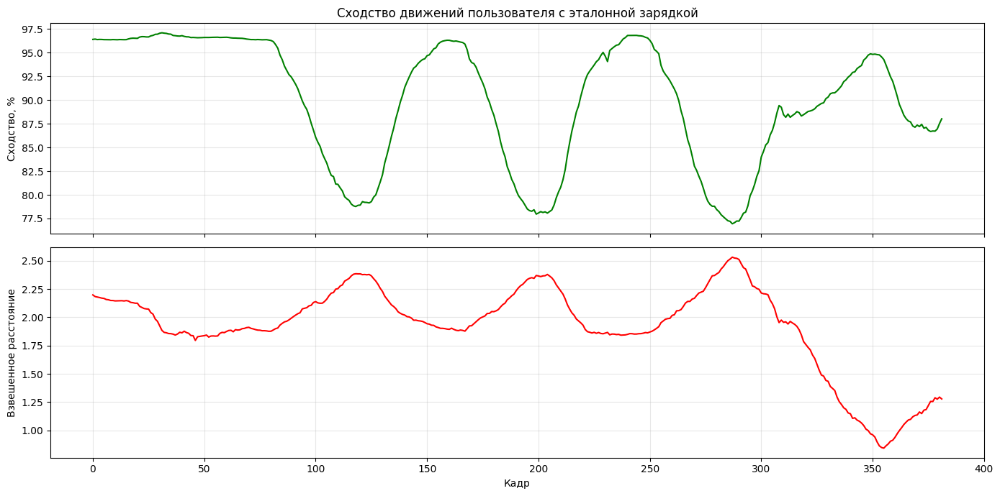

График сохранён: C:\Users\aleks\Documents\IDE\REAL-CV-5. Real Life CV\output\metrics_plot.png


In [11]:
display(Video(str(OUTPUT_VIDEO), embed=True, width=900))

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(metrics['frame'], metrics['similarity_percent'], color='green')
axes[0].set_title('Сходство движений пользователя с эталонной зарядкой')
axes[0].set_ylabel('Сходство, %')
axes[0].grid(alpha=0.3)
axes[1].plot(metrics['frame'], metrics['weighted_distance'], color='red')
axes[1].set_xlabel('Кадр')
axes[1].set_ylabel('Взвешенное расстояние')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=150)
plt.show()
print('График сохранён:', PLOT_PATH)